# Clinical Note Triage — from TF-IDF to transformer embeddings

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s7-clinical-note-triage.ipynb)

Read a free-text **medical transcription** and predict which of **12 clinical specialties**
(`spec_01` … `spec_12`) it belongs to: [challenge 174](https://ml-arena.com/viewchallenge/174)
on ML-Arena. Metric: **F1-macro**.

1. A **TF-IDF + logistic regression** baseline, submitted.
2. The same notes through a pretrained model from **Hugging Face**: text → tokens → embeddings
   → one vector per note.
3. Explore that vector space, then train an **MLP** on it.
4. Your turn: pick other models on Hugging Face, compare them, submit the best.

> In Colab: **Runtime → Change runtime type → T4 GPU**, then run the cells top to bottom.
> The only thing you must edit is your API token (your **Profile** page on ml-arena.com).

## 0. Setup

In [2]:
!pip install -q "mlarena-sdk>=3" transformers scikit-learn pandas matplotlib
from google.colab import userdata

import mlarena
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

API_TOKEN = userdata.get('api_key_mlarena')   # <-- paste your token (Profile page)
CHALLENGE_ID = 174

client = mlarena.connect(api_key=API_TOKEN, base_url="https://ml-arena.com")

## 1. Get the data

`train.csv` holds `id, transcription, label`; `test.csv` holds `id, transcription`. Every model
below is scored on the **same** held-out 20 % of the training notes, so the numbers compare.

In [3]:
client.download_dataset(CHALLENGE_ID, "data/")
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

y = train["label"].values
classes = sorted(set(y))
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=0.2,
                                   random_state=0, stratify=y)
print("train:", train.shape, "  test:", test.shape)
print(train["label"].value_counts().sort_index().to_dict())

train: (1951, 3)   test: (488, 2)
{'spec_01': 280, 'spec_02': 280, 'spec_03': 178, 'spec_04': 280, 'spec_05': 77, 'spec_06': 124, 'spec_07': 217, 'spec_08': 178, 'spec_09': 66, 'spec_10': 124, 'spec_11': 72, 'spec_12': 75}


Read a few notes before modelling. The specialty is hidden behind a code (`spec_01` …).

In [4]:
for _, row in train.sample(3, random_state=1).iterrows():
    print(f"--- {row['label']}  ({len(row['transcription'].split())} words)")
    print(row["transcription"][:600], "...\n")

--- spec_02  (878 words)
PREOPERATIVE DIAGNOSES:,1. Right shoulder rotator cuff tear.,2. Glenohumeral rotator cuff arthroscopy.,3. Degenerative joint disease.,POSTOPERATIVE DIAGNOSES:,1. Right shoulder rotator cuff tear.,2. Glenohumeral rotator cuff arthroscopy.,3. Degenerative joint disease.,PROCEDURE PERFORMED: ,Right shoulder hemiarthroplasty.,ANESTHESIA: , General.,ESTIMATED BLOOD LOSS: , Approximately 125 cc.,COMPLICATIONS:, None.,COMPONENTS: , A DePuy 10 mm global shoulder system stem was used cemented and a DePuy 44 x 21 mm articulating head was used.,BRIEF HISTORY: ,The patient is an 82-year-old right-hand dom ...

--- spec_08  (419 words)
CC: ,Depressed mental status.,HX: ,29y/o female fell down a flight of stairs on 2/20/95, striking the right side of her head. She then walked over to and lay down on a living room couch. She was found there, the next morning, by her boyfriend, poorly responsive and amidst a coffee ground like emesis. She was taken to a local ER and HCT reveal

**Questions**
- Which words would let a clinician guess the specialty? Where in the note are they?
- What does the text look like around the section headers? Is it clean prose?

## 2. Baseline: TF-IDF + logistic regression

Each note becomes a sparse vector: one column per word of the vocabulary, its count in the
note down-weighted by how common the word is across notes. No notion of meaning:
*myocardial* and *cardiac* are unrelated columns.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

text = train["transcription"]
baseline = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
baseline.fit(text.iloc[idx_tr], y[idx_tr])
print("validation F1-macro: %.3f" % f1_score(y[idx_val], baseline.predict(text.iloc[idx_val]), average="macro"))

validation F1-macro: 0.470


Refit on all the training notes, predict the test set, submit.

In [6]:
baseline.fit(text, y)
pd.DataFrame({"id": test["id"], "label": baseline.predict(test["transcription"])}).to_csv("submission.csv", index=False)
client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"], submission_name="tfidf-logreg")

{'submission_id': 9091,
 'deploy': {'deployment_id': 8803,
  'is_deployable': False,
  'is_settled': False,
  'is_uploadable': False,
  'last_status_message': 'Deployment queued successfully',
  'message': 'Deployment started successfully',
  'phase': 'deployment',
  'status': 'deploy_queue',
  'status_update_ts': '2026-09-29T09:13:50.270159Z'}}

## 3. Text → tokens

A transformer never reads words. Its **tokenizer** cuts the text into **subword tokens** from a
fixed vocabulary and maps each one to an integer **id**. We start with **GPT-2** (124 M
parameters, byte-level BPE, pretrained on general web text).

`MODEL_NAME` and `POOLING` are the two lines you will change in Section 7.

In [7]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "openai-community/gpt2"
POOLING = "mean"                      # "mean" or "cls", see Section 4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sentence = "Laparoscopic cholecystectomy under general anesthesia, 40 mg IV."
print(tokenizer.tokenize(sentence))
print(tokenizer(sentence)["input_ids"])

n_tokens = train["transcription"].map(lambda t: len(tokenizer(t)["input_ids"]))
print("vocabulary:", len(tokenizer), "  tokens per note:", n_tokens.describe()[["50%", "max"]].to_dict())

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1203 > 1024). Running this sequence through the model will result in indexing errors


['L', 'ap', 'ar', 'oscopic', 'Ġcho', 'le', 'cy', 'st', 'ectomy', 'Ġunder', 'Ġgeneral', 'Ġanesthesia', ',', 'Ġ40', 'Ġmg', 'ĠIV', '.']
[43, 499, 283, 48228, 1727, 293, 948, 301, 42505, 739, 2276, 49592, 11, 2319, 10527, 8363, 13]
vocabulary: 50257   tokens per note: {'50%': 598.0, 'max': 3553.0}


**Questions**
- How is each medical word split? What does the `Ġ` prefix encode?
- What fraction of the notes is longer than 512 tokens? Below we **truncate** at 512: which
  part of a note is lost, and does it matter for guessing the specialty?

## 4. Tokens → one vector per note

The model looks up a vector for each token id, then mixes them through its attention layers.
`last_hidden_state` has shape `(batch, n_tokens, hidden_size)`: one **contextual** vector per
token. The classifier needs **one** vector per note, so we **pool**:

- **`cls`**: BERT-style encoders put a `[CLS]` token first and pretrain it to summarise the
  sequence, so take `h[:, 0]`.
- **`mean`**: average the token vectors, skipping padding with the attention mask $m_t$:

$$e = \frac{\sum_t m_t\, h_t}{\sum_t m_t}$$

GPT-2 is a decoder: each token attends only to the tokens before it, so its first token has
seen nothing of the note, and mean pooling is the natural choice.

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
if tokenizer.pad_token is None:          # GPT-2 was pretrained without padding
    tokenizer.pad_token = tokenizer.eos_token

@torch.no_grad()
def embed(texts, batch_size=16, max_length=512):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state                 # (batch, n_tokens, hidden)
        if POOLING == "cls":
            e = h[:, 0]
        else:
            m = enc["attention_mask"].unsqueeze(-1)         # 1 = token, 0 = padding
            e = (h * m).sum(1) / m.sum(1)
        out.append(e.float().cpu().numpy())
    return np.vstack(out)

X = embed(train["transcription"].tolist())
X_test = embed(test["transcription"].tolist())
print("embeddings:", X.shape, X_test.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

embeddings: (1951, 768) (488, 768)


### Look inside: attention on one sentence

Each layer lets every token build its vector from the others. Row *i* of an attention map is
how much token *i* (the query) takes from each token (the keys). GPT-2 has 12 layers of 12
heads; here are three of them, on GPT-2 whatever `MODEL_NAME` is.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

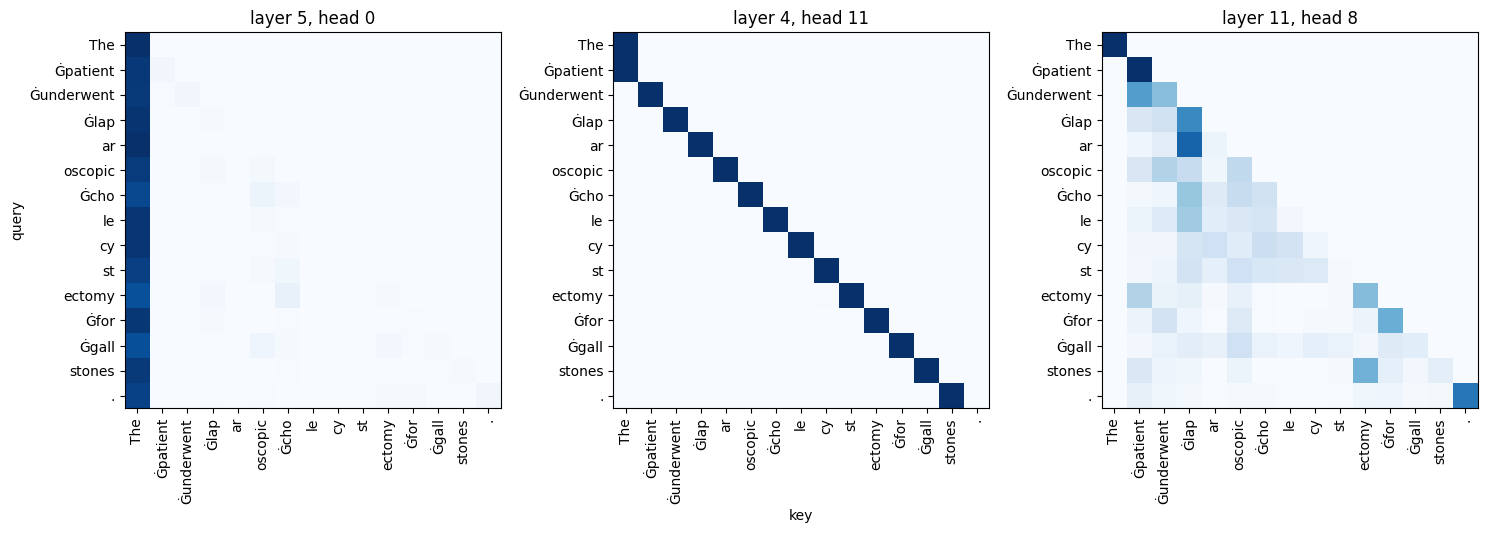

In [9]:
gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
viewer = AutoModel.from_pretrained("openai-community/gpt2", attn_implementation="eager")  # eager returns the weights
enc = gpt2_tok("The patient underwent laparoscopic cholecystectomy for gallstones.", return_tensors="pt")
with torch.no_grad():
    attentions = viewer(**enc, output_attentions=True).attentions   # per layer: (1, heads, n, n)
tokens = gpt2_tok.convert_ids_to_tokens(enc["input_ids"][0])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (layer, head) in zip(axes, [(5, 0), (4, 11), (11, 8)]):
    ax.imshow(attentions[layer][0, head], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)), tokens, rotation=90); ax.set_yticks(range(len(tokens)), tokens)
    ax.set_title(f"layer {layer}, head {head}")
axes[0].set_ylabel("query"); axes[1].set_xlabel("key")
plt.tight_layout(); plt.show()

**Questions**
- Why is everything above the diagonal zero? Would it be with a BERT model?
- Each row sums to 1. Why does the first head send almost everything to `The`?
- What does the second head do? And in the third, which tokens does `stones` look at?

## 5. Explore the embedding space

Two notes are compared by the angle between their vectors, the **cosine similarity**
$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert\, \lVert b \rVert}$. Average the training
vectors of each specialty into a **centroid**, then classify a validation note by its most
similar centroid: no training at all.

nearest-centroid validation F1-macro: 0.202


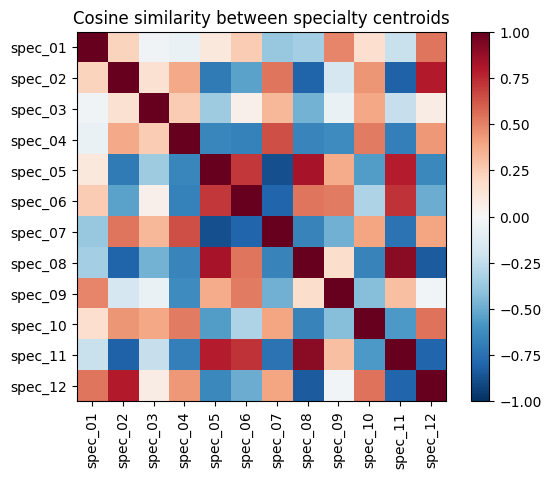

In [10]:
from sklearn.metrics.pairwise import cosine_similarity

Z = X - X[idx_tr].mean(0)                # centre the cloud (see the questions)
centroids = np.stack([Z[idx_tr][y[idx_tr] == c].mean(0) for c in classes])
nearest = np.array(classes)[cosine_similarity(Z[idx_val], centroids).argmax(1)]
print("nearest-centroid validation F1-macro: %.3f" % f1_score(y[idx_val], nearest, average="macro"))

plt.imshow(cosine_similarity(centroids), cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(12), classes, rotation=90); plt.yticks(range(12), classes)
plt.colorbar(); plt.title("Cosine similarity between specialty centroids"); plt.show()

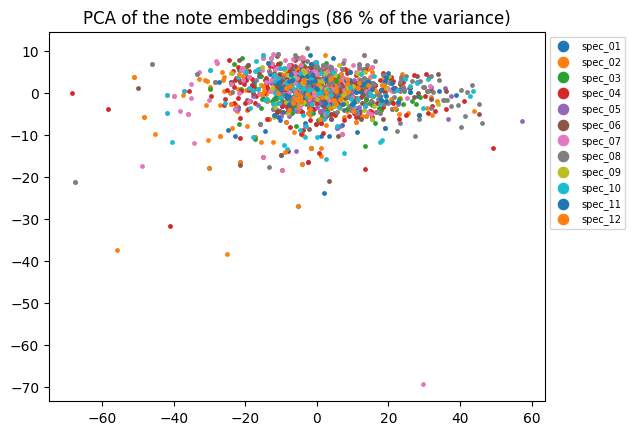

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(Z[idx_tr])
P = pca.transform(Z[idx_tr])
for c in classes:
    plt.scatter(*P[y[idx_tr] == c].T, s=6, label=c)
plt.legend(markerscale=3, fontsize=7, bbox_to_anchor=(1, 1))
plt.title("PCA of the note embeddings (%.0f %% of the variance)" % (100 * pca.explained_variance_ratio_.sum()))
plt.show()

In [14]:
cosine_similarity(X[:100]).mean()

np.float32(0.998118)

**Questions**
- Print `cosine_similarity(X[:100]).mean()` on the raw, uncentred embeddings. What do you
  get, and why does it make raw cosine similarity useless here?
- Which specialties are closest to each other? Are they also the ones the baseline confuses?
- Do the specialties form clusters in the PCA plot? How much of the variance do these two
  axes keep?

## 6. An MLP on the embeddings

The pretrained model stays frozen; only a small classifier is trained on its vectors.

In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

labels = LabelEncoder().fit(y)           # the MLP's early stopping needs integer labels
mlp = make_pipeline(StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-2, early_stopping=True,
                                  max_iter=500, random_state=0))
mlp.fit(X[idx_tr], labels.transform(y[idx_tr]))
pred = labels.inverse_transform(mlp.predict(X[idx_val]))
print("validation F1-macro: %.3f" % f1_score(y[idx_val], pred, average="macro"))

validation F1-macro: 0.555


Submit it once it beats your previous best on the validation split.

In [13]:
mlp.fit(X, labels.transform(y))
pd.DataFrame({"id": test["id"], "label": labels.inverse_transform(mlp.predict(X_test))}).to_csv("submission.csv", index=False)
client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"],
              submission_name=f"{MODEL_NAME.split('/')[-1]}-{POOLING}-mlp")

{'submission_id': 9092,
 'deploy': {'deployment_id': 8804,
  'is_deployable': False,
  'is_settled': False,
  'is_uploadable': False,
  'last_status_message': 'Deployment queued successfully',
  'message': 'Deployment started successfully',
  'phase': 'deployment',
  'status': 'deploy_queue',
  'status_update_ts': '2026-09-29T09:16:05.110003Z'}}

## 7. Your turn: choose the model

Change `MODEL_NAME` and `POOLING` in Section 3, rerun Sections 3 to 6, and keep a table:

| model | encoder / decoder | parameters | pretraining corpus | vocabulary | median tokens per note | pooling | validation F1 |
|---|---|---|---|---|---|---|---|

Some starting points (read each **model card** on huggingface.co before running it):

- general English: `google-bert/bert-base-uncased`, `distilbert/distilbert-base-uncased`,
  `FacebookAI/roberta-base`, `openai-community/gpt2-medium`, `Qwen/Qwen2.5-0.5B`
- trained for sentence similarity: `sentence-transformers/all-MiniLM-L6-v2`, `BAAI/bge-small-en-v1.5`
- scientific and biomedical text: `allenai/scibert_scivocab_uncased`,
  `dmis-lab/biobert-base-cased-v1.2`,
  `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext`,
  `NeuML/pubmedbert-base-embeddings`
- clinical notes: `emilyalsentzer/Bio_ClinicalBERT`

Or search the hub yourself: [feature-extraction](https://huggingface.co/models?pipeline_tag=feature-extraction)
and [sentence-similarity](https://huggingface.co/models?pipeline_tag=sentence-similarity) models.

**Questions**
- Which pooling suits each model, and why? Try both on one encoder: does the answer match?
- Tokenize the Section 3 sentence with each tokenizer. Does a vocabulary that keeps medical
  words whole go with a better score?
- Which matters more here, the size of the model or the corpus it was pretrained on?
- Which specialties does your best model still get wrong (`classification_report`)? Does
  TF-IDF get them right?- The validation split has about 390 notes. How large must a gap in F1-macro be before you
  believe it?

In [42]:
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM

MODEL_NAME = "emilyalsentzer/Bio_ClinicalBERT"
POOLING = "cls"                      # "mean" or "cls", see Section 4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sentence = "Laparoscopic cholecystectomy under general anesthesia, 40 mg IV."
print(tokenizer.tokenize(sentence))
print(tokenizer(sentence)["input_ids"])

n_tokens = train["transcription"].map(lambda t: len(tokenizer(t)["input_ids"]))
print("vocabulary:", len(tokenizer), "  tokens per note:", n_tokens.describe()[["50%", "max"]].to_dict())

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

['lap', '##aro', '##scopic', 'ch', '##ole', '##cy', '##ste', '##ct', '##omy', 'under', 'general', 'an', '##est', '##hesia', ',', '40', 'mg', 'i', '##v', '.']
[101, 4443, 14452, 21442, 22572, 9016, 3457, 13894, 5822, 18574, 1223, 1704, 1126, 2556, 27300, 117, 1969, 17713, 178, 1964, 119, 102]
vocabulary: 28996   tokens per note: {'50%': 636.0, 'max': 3767.0}


In [43]:

device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
if tokenizer.pad_token is None:          # GPT-2 was pretrained without padding
    tokenizer.pad_token = tokenizer.eos_token

@torch.no_grad()
def embed(texts, batch_size=16, max_length=512):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state                 # (batch, n_tokens, hidden)
        if POOLING == "cls":
            e = h[:, 0]
        else:
            m = enc["attention_mask"].unsqueeze(-1)         # 1 = token, 0 = padding
            e = (h * m).sum(1) / m.sum(1)
        out.append(e.float().cpu().numpy())
    return np.vstack(out)

X = embed(train["transcription"].tolist())
X_test = embed(test["transcription"].tolist())
print("embeddings:", X.shape, X_test.shape)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


embeddings: (1951, 768) (488, 768)


nearest-centroid validation F1-macro: 0.353


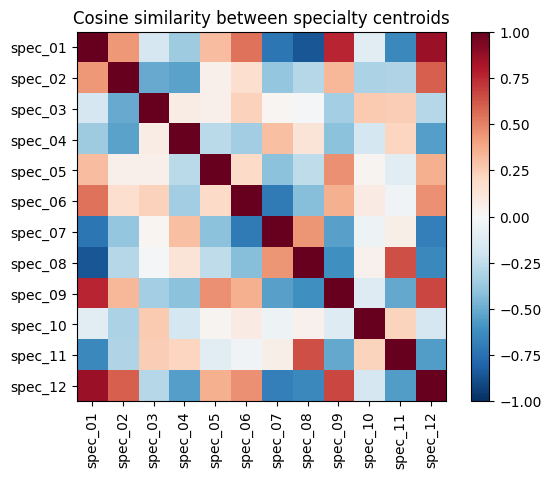

In [44]:
from sklearn.metrics.pairwise import cosine_similarity

Z = X - X[idx_tr].mean(0)                # centre the cloud (see the questions)
centroids = np.stack([Z[idx_tr][y[idx_tr] == c].mean(0) for c in classes])
nearest = np.array(classes)[cosine_similarity(Z[idx_val], centroids).argmax(1)]
print("nearest-centroid validation F1-macro: %.3f" % f1_score(y[idx_val], nearest, average="macro"))

plt.imshow(cosine_similarity(centroids), cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(12), classes, rotation=90); plt.yticks(range(12), classes)
plt.colorbar(); plt.title("Cosine similarity between specialty centroids"); plt.show()

nearest-centroid validation F1-macro: 0.353


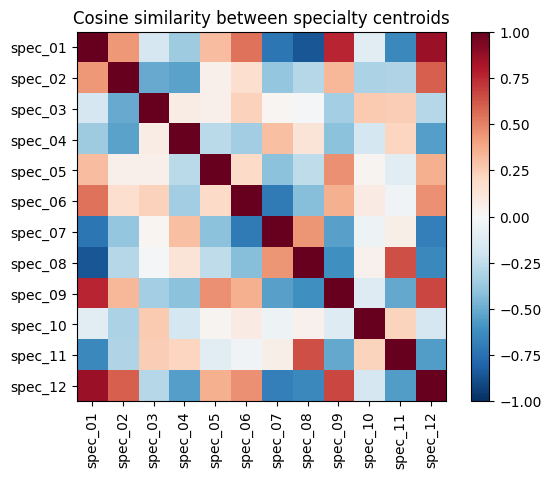

In [45]:
from sklearn.metrics.pairwise import cosine_similarity

Z = X - X[idx_tr].mean(0)                # centre the cloud (see the questions)
centroids = np.stack([Z[idx_tr][y[idx_tr] == c].mean(0) for c in classes])
nearest = np.array(classes)[cosine_similarity(Z[idx_val], centroids).argmax(1)]
print("nearest-centroid validation F1-macro: %.3f" % f1_score(y[idx_val], nearest, average="macro"))

plt.imshow(cosine_similarity(centroids), cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(12), classes, rotation=90); plt.yticks(range(12), classes)
plt.colorbar(); plt.title("Cosine similarity between specialty centroids"); plt.show()

In [46]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

labels = LabelEncoder().fit(y)           # the MLP's early stopping needs integer labels
mlp = make_pipeline(StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-2, early_stopping=True,
                                  max_iter=500, random_state=0))
mlp.fit(X[idx_tr], labels.transform(y[idx_tr]))
pred = labels.inverse_transform(mlp.predict(X[idx_val]))
print("validation F1-macro: %.3f" % f1_score(y[idx_val], pred, average="macro"))

validation F1-macro: 0.536
